# Lab 9: Expectation-maximization and Gaussian mixtures

In [1]:
import pandas as pd
from scipy.stats import norm
import math
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

gdata = pd.read_csv("./gdata.txt")
x = gdata.loc[:, "X"]
y = gdata.loc[:, "Y"]

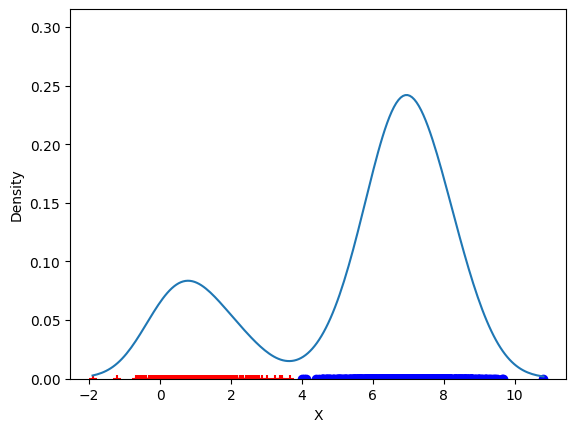

In [2]:
plt.scatter(x[(y == 1)], np.zeros(len(x[(y == 1)].tolist())), c="red", marker="+")
plt.scatter(x[(y == 2)], np.zeros(len(x[(y == 2)].tolist())), c="blue", marker="o")
sns.histplot(x, kde=True, stat="density", linewidth=0, fill=False)
plt.show()

In [3]:
mu = [0, 1]
lamda = [0.5, 0.5]
epsilon = 1e-08
log_likelihood = np.sum([math.log(i) for i in lamda[0] * norm.pdf(x, loc=mu[0], scale=1) + lamda[1] * norm.pdf(x, loc=mu[1], scale=1)])

In [4]:
while True:
    T1 = norm.pdf(x, loc=mu[0], scale=1)
    T2 = norm.pdf(x, loc=mu[1], scale=1)
    P1 = lamda[0] * T1 / (lamda[0] * T1 + lamda[1] * T2)
    P2 = lamda[1] * T2 / (lamda[0] * T1 + lamda[1] * T2)

    mu[0] = np.sum(P1 * x) / np.sum(P1)
    mu[1] = np.sum(P2 * x) / np.sum(P2)
    lamda[0] = np.mean(P1)
    lamda[1] = np.mean(P2)

    new_log_likelihood = np.sum([math.log(i) for i in lamda[0] * norm.pdf(x, loc=mu[0], scale=1) + lamda[1] * norm.pdf(x, loc=mu[1], scale=1)])

    print("mu=", mu, " lambda=", lamda, " log_likelihood=", new_log_likelihood)
    if ((new_log_likelihood - log_likelihood) <= epsilon): break
    log_likelihood = new_log_likelihood

mu= [0.6481654224611784, 6.03818468302204]  lambda= [0.10195238498539352, 0.8980476150146064]  log_likelihood= -2412.1359422146006
mu= [0.9268449875753101, 6.941004495395096]  lambda= [0.24148763085117073, 0.7585123691488292]  log_likelihood= -1989.682033388186
mu= [0.9983299950159288, 6.982970277433431]  lambda= [0.2496910161055075, 0.7503089838944925]  log_likelihood= -1988.1243060523857
mu= [1.0028940005263036, 6.984687860174045]  lambda= [0.250096966058187, 0.7499030339418131]  log_likelihood= -1988.1199262789596
mu= [1.0031495322266093, 6.984779969381971]  lambda= [0.25011919756828327, 0.7498808024317168]  log_likelihood= -1988.1199129136435
mu= [1.0031636820224707, 6.984785056585916]  lambda= [0.2501204269894889, 0.7498795730105111]  log_likelihood= -1988.1199128727262
mu= [1.0031644650336762, 6.9847853380566365]  lambda= [0.2501204950172442, 0.7498795049827559]  log_likelihood= -1988.1199128726012


In [5]:
from sklearn.mixture import GaussianMixture
data = np.array(x.tolist()).reshape(-1,1)
gm = GaussianMixture(random_state=0, n_components=2).fit(data)
print(gm.means_)
print(gm.covariances_)
print(np.sum(gm.score_samples(data)))

[[6.98211528]
 [0.99612888]]
[[[1.06081375]]

 [[0.90908071]]]
-1987.0764998493853


In [6]:
def mix_pdf(x, loc, scale, weights):
    d = np.zeros_like(x)
    for mu, sigma, pi in zip(loc, scale, weights):
        d += pi * norm.pdf(x, loc = mu, scale = sigma)
    return d

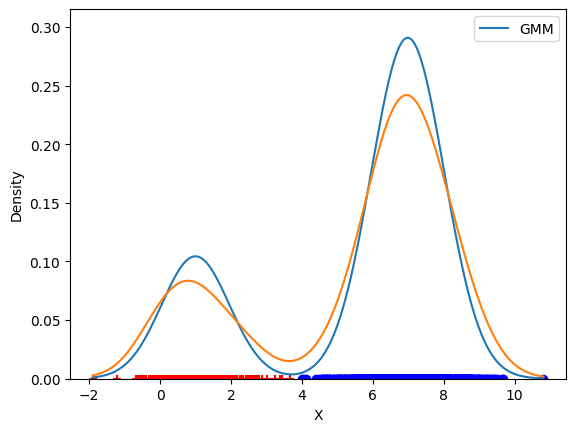

In [7]:
pi, mu, sigma = gm.weights_.flatten(), gm.means_.flatten(), np.sqrt(gm.covariances_.flatten())
grid = np.arange(np.min(x), np.max(x), 0.01)
plt.scatter(x[(y == 1)], np.zeros(len(x[(y == 1)].tolist())), c="red", marker="+")
plt.scatter(x[(y == 2)], np.zeros(len(x[(y == 2)].tolist())), c="blue", marker="o")
plt.plot(grid, mix_pdf(grid, mu, sigma, pi), label="GMM")
sns.histplot(x, kde=True, stat="density", linewidth=0, fill=False)
plt.legend(loc = 'upper right')
plt.show()

In [8]:
gsdata = pd.read_csv("./gsdata.txt")
target = gsdata.loc[:, "Y"]
gsdata = gsdata.drop(["Y"], axis=1)

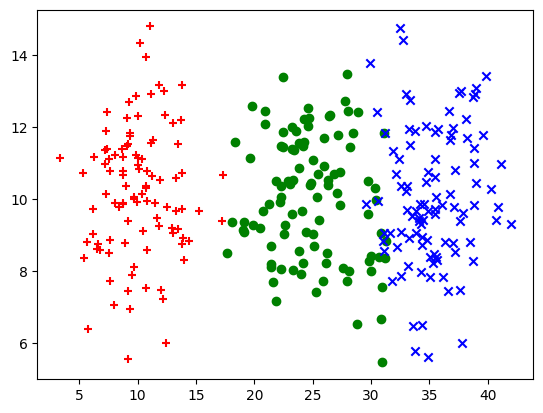

In [9]:
plt.scatter(gsdata[(target == 1)].X1, gsdata[(target == 1)].X2, c="red", marker="+")
plt.scatter(gsdata[(target == 2)].X1, gsdata[(target == 2)].X2, c="green", marker="o")
plt.scatter(gsdata[(target == 3)].X1, gsdata[(target == 3)].X2, c="blue", marker="x")
plt.show()

In [10]:
gm = GaussianMixture(random_state=0, n_components=3, tol=0.1).fit(gsdata)

In [11]:
x = np.linspace(np.min(gsdata.loc[:, "X1"]), np.max(gsdata.loc[:, "X1"]))
y = np.linspace(np.min(gsdata.loc[:, "X2"]), np.max(gsdata.loc[:, "X2"]))
X, Y = np.meshgrid(x, y)
XX = np.array([X.ravel(), Y.ravel()]).T
Z = -gm.score_samples(XX)
Z = Z.reshape(X.shape)

.../site-packages/sklearn/base.py:493: UserWarning: X does not have valid feature names, but GaussianMixture was fitted with feature names
  warnings.warn(


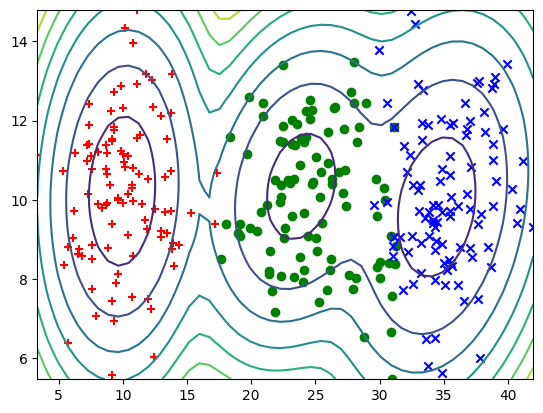

In [12]:
plt.contour(X, Y, Z)
plt.scatter(gsdata[(target == 1)].X1, gsdata[(target == 1)].X2, c="red", marker="+")
plt.scatter(gsdata[(target == 2)].X1, gsdata[(target == 2)].X2, c="green", marker="o")
plt.scatter(gsdata[(target == 3)].X1, gsdata[(target == 3)].X2, c="blue", marker="x")
plt.show()

In [13]:
clusters = gm.predict(gsdata)
centers = gm.means_

In [14]:
from sklearn.metrics import silhouette_score
print(silhouette_score(gsdata, clusters))

0.6139540686918329


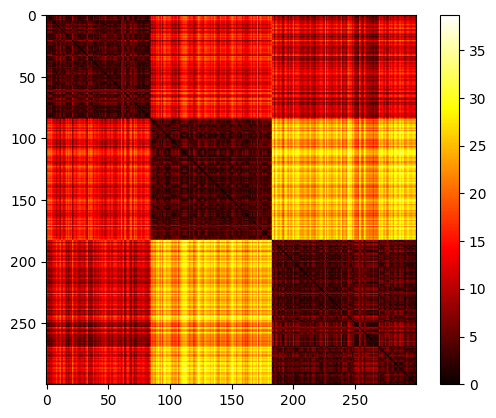

In [15]:
gsdata["cluster"] = clusters
gsdata = gsdata.sort_values("cluster").drop("cluster", axis=1)
from scipy.spatial import distance_matrix
dist = distance_matrix(gsdata, gsdata)
plt.imshow(dist, cmap='hot')
plt.colorbar()
plt.show()

In [16]:
icdata = pd.read_csv("./icdata.txt")
x = icdata.loc[:, "X"]
y = icdata.loc[:, "Y"]
data = np.array(x.tolist()).reshape(-1,1)

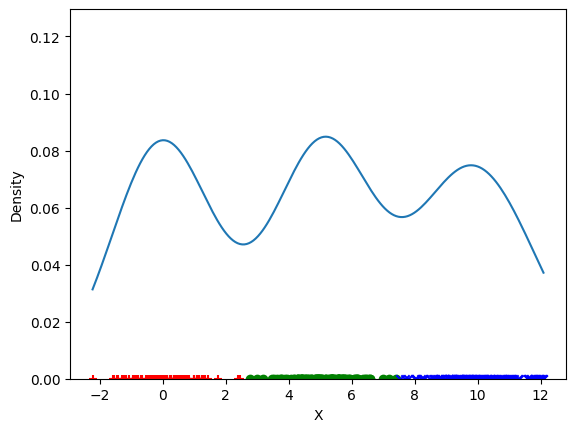

In [17]:
plt.scatter(x[(y == 1)], np.zeros(len(x[(y == 1)].tolist())), c="red", marker="+")
plt.scatter(x[(y == 2)], np.zeros(len(x[(y == 2)].tolist())), c="green", marker="o")
plt.scatter(x[(y == 3)], np.zeros(len(x[(y == 3)].tolist())), c="blue", marker="x")
sns.histplot(x, kde=True, stat="density", linewidth=0, fill=False)
plt.show()

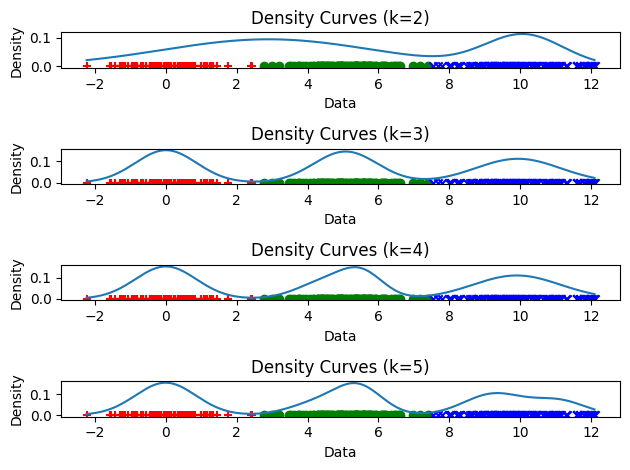

In [18]:
fig, axs = plt.subplots(4, 1)
n = [2, 3, 4, 5]
AIC = []
BIC = []
for i in n:
    gm = GaussianMixture(random_state=0, n_components=i).fit(data)
    pi, mu, sigma = gm.weights_.flatten(), gm.means_.flatten(), np.sqrt(gm.covariances_.flatten())
    grid = np.arange(np.min(x), np.max(x), 0.01)
    axs[i - 2].scatter(x[(y == 1)], np.zeros(len(x[(y == 1)].tolist())), c="red", marker="+")
    axs[i - 2].scatter(x[(y == 2)], np.zeros(len(x[(y == 2)].tolist())), c="green", marker="o")
    axs[i - 2].scatter(x[(y == 3)], np.zeros(len(x[(y == 3)].tolist())), c="blue", marker="x")
    axs[i - 2].plot(grid, mix_pdf(grid, mu, sigma, pi), label="GMM")
    axs[i - 2].set_title("Density Curves (k=" + str(i) + ")")
    axs[i - 2].set_xlabel("Data")
    axs[i - 2].set_ylabel("Density")
    AIC.append(gm.aic(data))
    BIC.append(gm.bic(data))
fig.tight_layout()
plt.show()

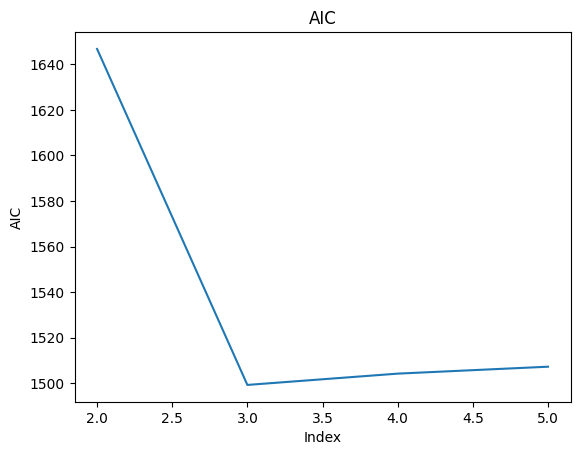

In [19]:
plt.plot(n, AIC)
plt.title("AIC")
plt.xlabel("Index")
plt.ylabel("AIC")
plt.show()

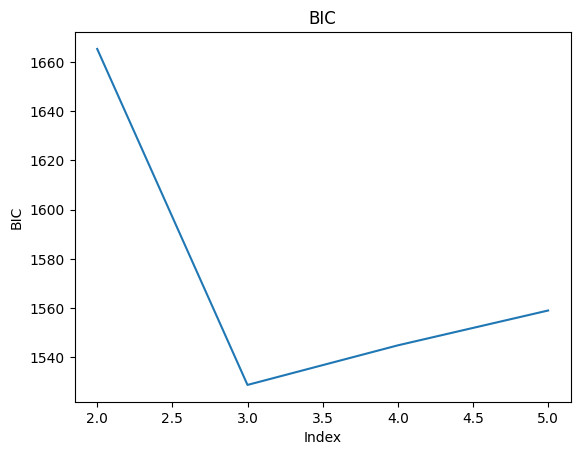

In [20]:
plt.plot(n, BIC)
plt.title("BIC")
plt.xlabel("Index")
plt.ylabel("BIC")
plt.show()